# [Clustering] Submission Akhir BMLP - Muhammad Arya Fatthurahman

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer
import joblib
import warnings
warnings.filterwarnings('ignore')

# Patch yellowbrick isclusterer for sklearn >= 1.6 compatibility
from yellowbrick.utils.types import isclusterer as _orig_isclusterer
def _patched_isclusterer(estimator):
    val = getattr(estimator, '_estimator_type', None)
    if val == 'clusterer':
        return True
    try:
        tags = estimator.__sklearn_tags__()
        return getattr(tags, 'estimator_type', None) == 'clusterer'
    except Exception:
        return _orig_isclusterer(estimator)
import yellowbrick.utils.types
yellowbrick.utils.types.isclusterer = _patched_isclusterer
import yellowbrick.cluster.base
yellowbrick.cluster.base.isclusterer = _patched_isclusterer

## Kriteria 1: Memuat Dataset dan Exploratory Data Analysis (EDA)

In [2]:
df = pd.read_csv('dataset.csv')
df.head()

,TransactionID,AccountID,DeviceID,IPAddress,MerchantID,TransactionDate,Amount,TransactionHour,TransactionDay,MerchantCategory,TransactionType,Location,IsFraud
0,TXN001001,ACC02001,DEV3001,173.57.12.190,MERCH4001,2023-07-16 20:31:00,338.20,20,16,Entertainment,Transfer,Jakarta,0
1,TXN001002,ACC02002,DEV3002,80.125.114.36,MERCH4002,2023-10-20 19:30:00,6.04,19,20,Clothing,Transfer,Yogyakarta,0
2,TXN001003,ACC02003,DEV3003,198.52.44.152,MERCH4003,2023-01-20 05:17:00,197.35,5,20,Grocery,Online,Jakarta,0
3,TXN001004,ACC02004,DEV3004,118.16.15.24,MERCH4004,2023-07-26 04:39:00,143.68,4,26,Travel,Online,Bandung,0
4,TXN001005,ACC02005,DEV3005,65.119.13.144,MERCH4005,2023-11-08 21:44:00,211.90,21,8,Utilities,Online,Bandung,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   TransactionID     1000 non-null   str    
 1   AccountID         1000 non-null   str    
 2   DeviceID          1000 non-null   str    
 3   IPAddress         1000 non-null   str    
 4   MerchantID        1000 non-null   str    
 5   TransactionDate   1000 non-null   str    
 6   Amount            1000 non-null   float64
 7   TransactionHour   1000 non-null   int64  
 8   TransactionDay    1000 non-null   int64  
 9   MerchantCategory  1000 non-null   str    
 10  TransactionType   1000 non-null   str    
 11  Location          1000 non-null   str    
 12  IsFraud           1000 non-null   int64  
dtypes: float64(1), int64(3), str(9)
memory usage: 101.7 KB


In [4]:
df.describe()

,Amount,TransactionHour,TransactionDay,IsFraud
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,205.993410,11.516000,15.710000,0.010000
std,140.285222,6.845919,8.749998,0.099549
min,5.000000,0.000000,1.000000,0.000000
25%,102.620000,6.000000,8.000000,0.000000
50%,172.905000,11.000000,16.000000,0.000000
75%,274.212500,17.000000,23.000000,0.000000
max,778.690000,23.000000,31.000000,1.000000


## Kriteria 2: Pembersihan dan Pra Pemrosesan Data

In [5]:
print("Jumlah missing values per kolom:")
print(df.isnull().sum())

Jumlah missing values per kolom:
TransactionID       0
AccountID           0
DeviceID            0
IPAddress           0
MerchantID          0
TransactionDate     0
Amount              0
TransactionHour     0
TransactionDay      0
MerchantCategory    0
TransactionType     0
Location            0
IsFraud             0
dtype: int64


In [6]:
print(f"Jumlah data duplikat: {df.duplicated().sum()}")

Jumlah data duplikat: 0


In [7]:
df_clean = df.dropna()
df_clean = df_clean.drop_duplicates()
print(f"Shape setelah cleaning: {df_clean.shape}")

Shape setelah cleaning: (1000, 13)


In [8]:
columns_to_drop = ['TransactionID', 'AccountID', 'DeviceID', 'IPAddress', 'MerchantID', 'TransactionDate']
df_clean = df_clean.drop(columns=columns_to_drop)
df_clean.head()

,Amount,TransactionHour,TransactionDay,MerchantCategory,TransactionType,Location,IsFraud
0,338.20,20,16,Entertainment,Transfer,Jakarta,0
1,6.04,19,20,Clothing,Transfer,Yogyakarta,0
2,197.35,5,20,Grocery,Online,Jakarta,0
3,143.68,4,26,Travel,Online,Bandung,0
4,211.90,21,8,Utilities,Online,Bandung,0


In [9]:
categorical_columns = df_clean.select_dtypes(include=['object']).columns.tolist()
print(f"Kolom kategorikal: {categorical_columns}")

label_encoders = {}
for col in categorical_columns:
    le = LabelEncoder()
    df_clean[col] = le.fit_transform(df_clean[col])
    label_encoders[col] = le

df_clean.head()

Kolom kategorikal: ['MerchantCategory', 'TransactionType', 'Location']


,Amount,TransactionHour,TransactionDay,MerchantCategory,TransactionType,Location,IsFraud
0,338.20,20,16,2,3,3,0
1,6.04,19,20,0,3,7,0
2,197.35,5,20,3,2,3,0
3,143.68,4,26,6,2,1,0
4,211.90,21,8,7,2,1,0


## Kriteria 3: Membangun Model Clustering

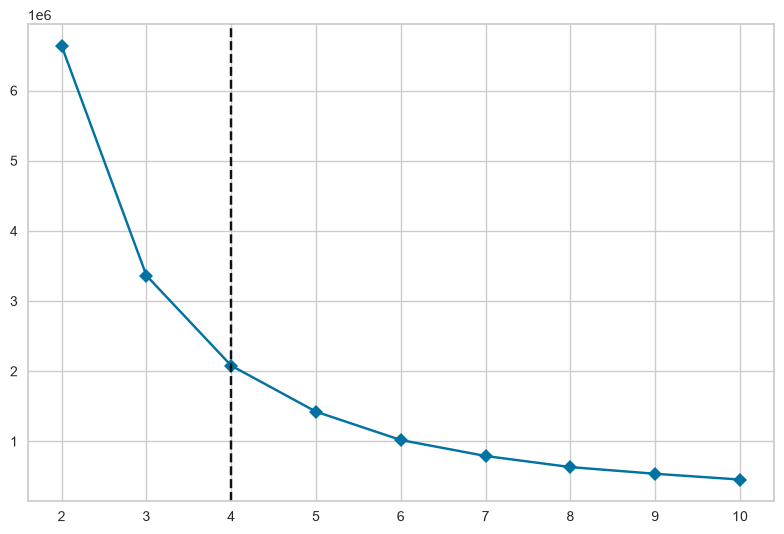

In [10]:
# Visualisasi Elbow Method menggunakan KElbowVisualizer
model = KMeans(n_init=10, random_state=42)
visualizer = KElbowVisualizer(model, k=(2, 11), timings=False)
visualizer.fit(df_clean)
plt.tight_layout()
plt.show()

In [11]:
# Menentukan k optimal dari KElbowVisualizer
optimal_k = visualizer.elbow_value_
print(f"Jumlah cluster optimal (berdasarkan Elbow Method): {optimal_k}")

kmeans = KMeans(n_clusters=optimal_k, n_init=10, random_state=42)
cluster_labels = kmeans.fit_predict(df_clean)

df_clean['Cluster'] = cluster_labels

Jumlah cluster optimal (berdasarkan Elbow Method): 4


In [12]:
# Simpan model clustering
joblib.dump(kmeans, 'model_clustering.h5')
print("Model clustering berhasil disimpan sebagai model_clustering.h5")

Model clustering berhasil disimpan sebagai model_clustering.h5


## Kriteria 4: Interpretasi Hasil Clustering

In [13]:
# Analisis deskriptif (mean, min, max) untuk fitur numerik
numeric_features = df_clean.select_dtypes(include=[np.number]).columns.tolist()
numeric_features = [f for f in numeric_features if f != 'Cluster']

print("Statistik deskriptif per cluster:")
descriptive_stats = df_clean.groupby('Cluster')[numeric_features].agg(['mean', 'min', 'max'])
descriptive_stats

Statistik deskriptif per cluster:


Amount                 TransactionHour         TransactionDay  \
               mean     min     max            mean min max           mean   
Cluster                                                                      
0         84.663376    5.00  141.11       11.350384   0  23      15.644501   
1        340.478436  269.45  439.19       11.916201   0  23      15.581006   
2        198.368239  141.73  265.86       11.673295   0  23      15.934659   
3        539.984231  443.18  778.69       10.717949   0  23      15.320513   

                MerchantCategory  ...     TransactionType          Location  \
        min max             mean  ... max            mean min max      mean   
Cluster                           ...                                         
0         1  31         3.442455  ...   7        1.677749   0   3  3.695652   
1         1  31         3.418994  ...   7        1.659218   0   3  3.681564   
2         1  31         3.477273  ...   7        1.764205   0   3  3.642045   
3         1  31         3.000000  ...   7        1.538462   0   3  3.410256   

                  IsFraud          
        min max      mean min max  
Cluster                            
0         0   7  0.000000   0   0  
1         0   7  0.011173   0   1  
2         0   7  0.000000   0   0  
3         0   7  0.102564   0   1  

[4 rows x 21 columns]

In [14]:
# Karakteristik tiap cluster
print("Karakteristik tiap cluster:")
cluster_profile = df_clean.groupby('Cluster')[numeric_features].mean()
cluster_profile

Karakteristik tiap cluster:


,Amount,TransactionHour,TransactionDay,MerchantCategory,TransactionType,Location,IsFraud
Cluster,,,,,,,
0,84.663376,11.350384,15.644501,3.442455,1.677749,3.695652,0.000000
1,340.478436,11.916201,15.581006,3.418994,1.659218,3.681564,0.011173
2,198.368239,11.673295,15.934659,3.477273,1.764205,3.642045,0.000000
3,539.984231,10.717949,15.320513,3.000000,1.538462,3.410256,0.102564


<Figure size 1200x600 with 0 Axes>

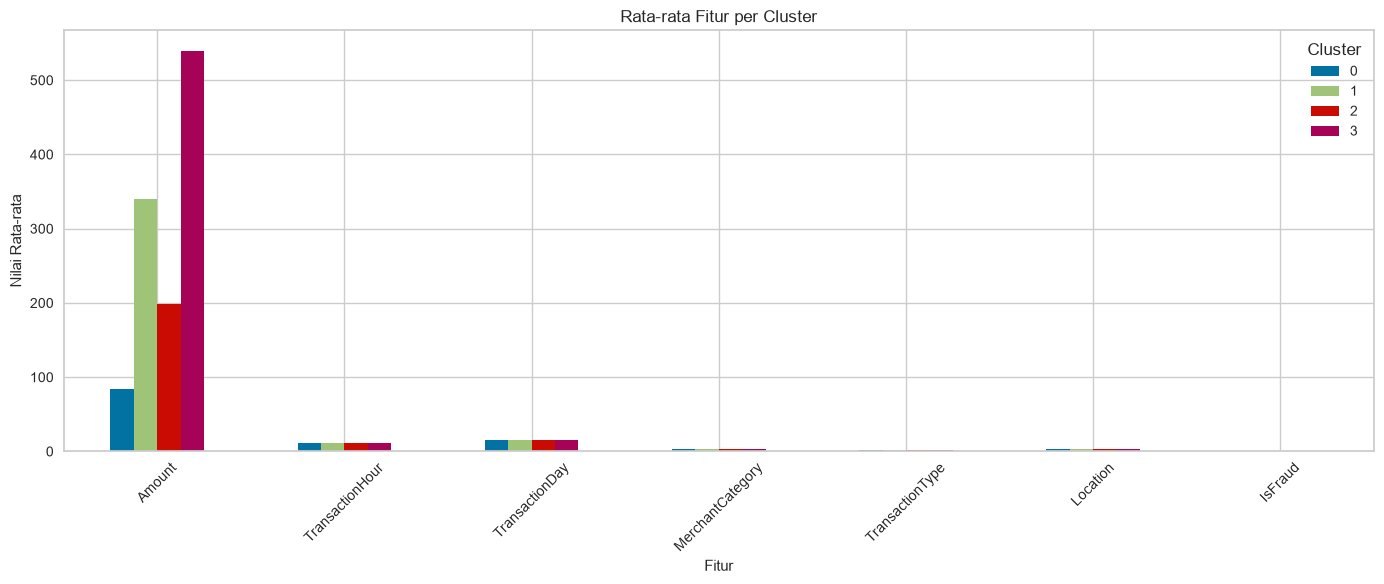

In [15]:
# Visualisasi karakteristik cluster
plt.figure(figsize=(12, 6))
cluster_profile.T.plot(kind='bar', figsize=(14, 6))
plt.title('Rata-rata Fitur per Cluster')
plt.xlabel('Fitur')
plt.ylabel('Nilai Rata-rata')
plt.legend(title='Cluster')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
# Ekspor data clustering dengan kolom Target
df_export = df_clean.rename(columns={'Cluster': 'Target'})
df_export.to_csv('data_clustering.csv', index=False)
print("Data clustering berhasil diekspor sebagai data_clustering.csv")
print(f"Shape data_clustering.csv: {df_export.shape}")
df_export.head()

Data clustering berhasil diekspor sebagai data_clustering.csv
Shape data_clustering.csv: (1000, 8)


,Amount,TransactionHour,TransactionDay,MerchantCategory,TransactionType,Location,IsFraud,Target
0,338.20,20,16,2,3,3,0,1
1,6.04,19,20,0,3,7,0,0
2,197.35,5,20,3,2,3,0,2
3,143.68,4,26,6,2,1,0,2
4,211.90,21,8,7,2,1,0,2
